## Assignment: $k$ Means Clustering


**Q1.** This is a question about clustering. We want to investigate how adjusting the "noisiness" of the data impacts the quality of the algorithm and the difficulty of picking $k$.

1. Run the code below, which creates four datasets: `df0_125`, `df0_25`, `df0_5`, `df1_0`, and `df2_0`. Each data set is created by increasing the amount of `noise` (standard deviation) around the cluster centers, from `0.125` to `0.25` to `0.5` to `1.0` to `2.0`.

```
import numpy as np
import pandas as pd

def createData(noise,N=50):
    np.random.seed(100) # Set the seed for replicability
    # Generate (x1,x2,g) triples:
    X1 = np.array([np.random.normal(1,noise,N),np.random.normal(1,noise,N)])
    X2 = np.array([np.random.normal(3,noise,N),np.random.normal(2,noise,N)])
    X3 = np.array([np.random.normal(5,noise,N),np.random.normal(3,noise,N)])
    # Concatenate into one data frame
    gdf1 = pd.DataFrame({'x1':X1[0,:],'x2':X1[1,:],'group':'a'})
    gdf2 = pd.DataFrame({'x1':X2[0,:],'x2':X2[1,:],'group':'b'})
    gdf3 = pd.DataFrame({'x1':X3[0,:],'x2':X3[1,:],'group':'c'})
    df = pd.concat([gdf1,gdf2,gdf3],axis=0)
    return df

df0_125 = createData(0.125)
df0_25 = createData(0.25)
df0_5 = createData(0.5)
df1_0 = createData(1.0)
df2_0 = createData(2.0)
```

2. Make scatterplots of the $(X1,X2)$ points by group for each of the datasets. As the `noise` goes up from 0.125 to 2.0, what happens to the visual distinctness of the clusters?
3. Create a scree plot for each of the datasets. Describe how the level of `noise` affects the scree plot (particularly the presence of a clear "elbow") and your ability to definitively select a $k$. (Pay attention to the vertical axis across plots, or put all the scree curves on a single canvas.)
4. Explain the intuition of the elbow, using this numerical simulation as an example.

**Q2.** This question is a case study on clustering.

1. Load the `SIPRI Military Expenditure Database.csv` file in the `./data` folder. This has data about military spending by country. Filter the rows to select only the year 2020, and drop all rows with missing values. I ended up with 148 countries. Is any further cleaning of the variables required?
2. Max-min normalize `Spending (2020 USD)` and `Spending per Capita`. Use a scree plot to determine the optimal number of clusters for the $k$ means clustering algorithm. Make a scatter plot of `Spending (2020 USD)` and `Spending per Capita`, and hue the dots by their cluster membership. Compute a describe table conditional on cluster membership (i.e. `.groupby(cluster).describe()`). What do you see? Where is the United States? Do you notice any patterns in the cluster membership?
3. Repeat part 2 for `Percent of Government Spending` and `Percent of GDP`. How do your results compare to part 2?
4. Use $k$ means clustering with all four numeric variables: `Spending (2020 USD)`, `Spending per Capita`, `Percent of Government Spending`, and `Percent of GDP`. How do your results compare to the previous two parts?
5. Did the $k$-MC algorithm find any useful patterns for you in analyzing the spending?

---

## *Phase 1: Solution without AI

Complete all questions in the following cells without generative AI. Then commit and push the
notebook before beginning Phase 2.

**Declaration:** I completed this version without generative AI.

**Student(s):** Will Keenan

**Date:** 10/12/2026

In [14]:
#Question 1.1
import numpy as np
import pandas as pd

def createData(noise,N=50):
    np.random.seed(100) # Set the seed for replicability
    # Generate (x1,x2,g) triples:
    X1 = np.array([np.random.normal(1,noise,N),np.random.normal(1,noise,N)])
    X2 = np.array([np.random.normal(3,noise,N),np.random.normal(2,noise,N)])
    X3 = np.array([np.random.normal(5,noise,N),np.random.normal(3,noise,N)])
    # Concatenate into one data frame
    gdf1 = pd.DataFrame({'x1':X1[0,:],'x2':X1[1,:],'group':'a'})
    gdf2 = pd.DataFrame({'x1':X2[0,:],'x2':X2[1,:],'group':'b'})
    gdf3 = pd.DataFrame({'x1':X3[0,:],'x2':X3[1,:],'group':'c'})
    df = pd.concat([gdf1,gdf2,gdf3],axis=0)
    return df

df0_125 = createData(0.125)
df0_25 = createData(0.25)
df0_5 = createData(0.5)
df1_0 = createData(1.0)
df2_0 = createData(2.0)

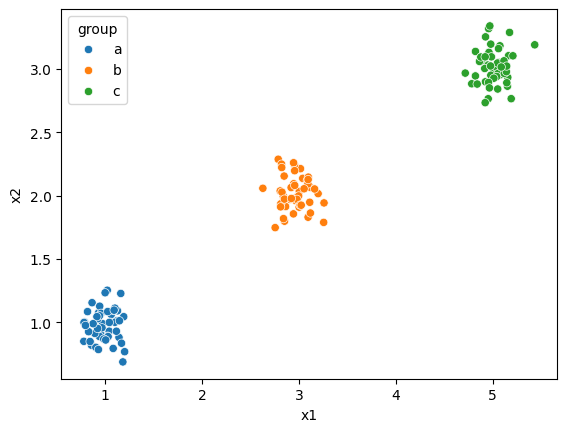

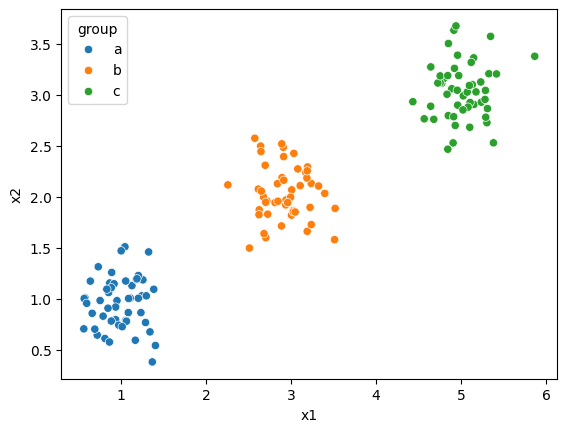

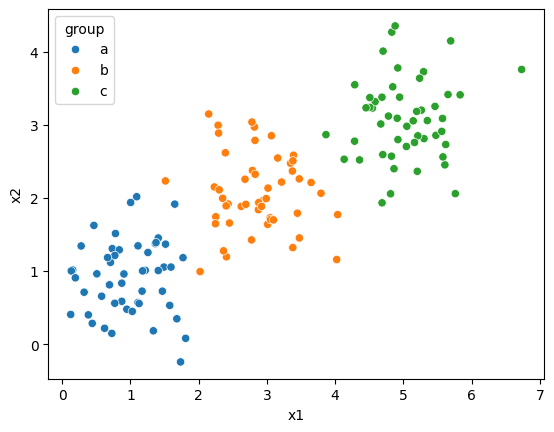

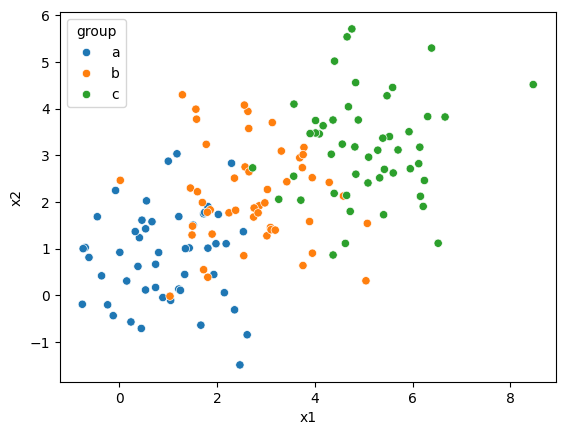

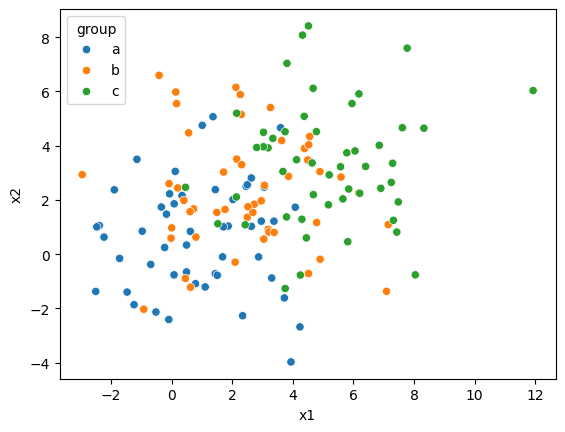

'\n0.125 and 0.25 the three clusters are tight and separate. At 0.5 they start to touch. At 1.0 and especially 2.0 they overlap heavily and look like one cloud.\n'

In [15]:
#Question 1.2:
import seaborn as sns
import matplotlib.pyplot as plt

for name, df in zip(['0.125','0.25','0.5','1.0','2.0'], [df0_125, df0_25, df0_5, df1_0, df2_0]):
    sns.scatterplot(data=df, x='x1', y='x2', hue='group')
    plt.show()

'''
0.125 and 0.25 the three clusters are tight and separate. At 0.5 they start to touch. At 1.0 and especially 2.0 they overlap heavily and look like one cloud.
'''

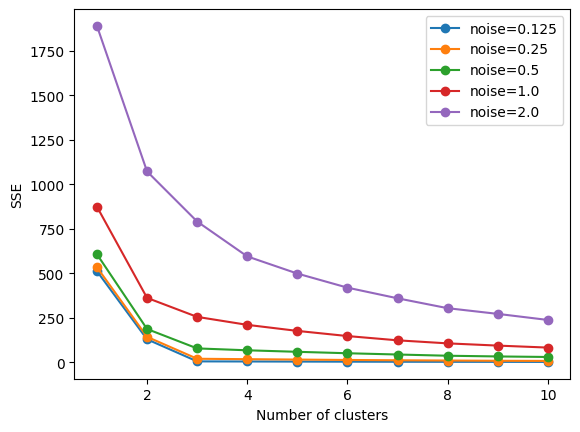

In [16]:
#Question 1.3
from sklearn.cluster import KMeans
import matplotlib.pyplot as plt

for name, d in zip(['0.125','0.25','0.5','1.0','2.0'], [df0_125, df0_25, df0_5, df1_0, df2_0]):
    SSE = [KMeans(n_clusters=k, n_init=10, random_state=100).fit(d[['x1', 'x2']]).inertia_
           for k in range(1, 11)]
    plt.plot(range(1, 11), SSE, marker='o', label=f'noise={name}')
plt.xlabel('Number of clusters'); plt.ylabel('SSE'); plt.legend()
plt.show()

'''
At low noise (0.125, 0.25) there is a sharp elbow at k = 3: SSE falls to about 1–4% of its k = 1 value and then barely changes.
As noise increases, the whole curve shifts upward and the bend softens. At 0.5 the elbow at 3 is still visible.
At 1.0 it’s weak, and at 2.0 the curve declines smoothly with no clear elbow (k = 3 → 4 still cuts SSE by about 25%).

With low noise I can confidently pick k = 3, which matches the true number of groups.
As noise increases, that choice becomes a judgment call, and at noise 2.0 I couldn’t defend k = 3 over 2 or 4 from the scree plot alone.
This matches the slides’ “No Clear Elbow” case: when the data doesn’t contain distinct groups, the elbow method doesn’t give a clear k.
'''

In [ ]:
#Question 1.4
'''
SSE is the total squared distance from each point to its assigned centroid.
Aadding clusters always lowers SSE, so we can’t simply minimize it; we look for where the improvement drops off.
In this simulation there are 3 true groups. While k < 3, at least one centroid has to cover two real groups, so its points are far from it.
 Adding a centroid separates a real group and causes a large drop in SSE (e.g., 512 → 129 → 4.9 at noise 0.125).
 Once k = 3, every group has its own centroid. Any extra centroid only splits a group into pieces, which barely reduces SSE (4.9 → 4.3).
 The elbow is that switch from big gains to small gains, and it sits at the true number of clusters.

Noise blurs this. When the groups overlap, the “real” splits don’t help as much, and splitting a wide, noisy group helps more.
The two kinds of gains end up similar in size, and the elbow disappears.
'''

In [19]:
#Question 2.1
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.cluster import KMeans
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.neighbors import KNeighborsClassifier
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import accuracy_score, classification_report
!git clone https://github.com/willhk10-uva/A04-clustering
df = pd.read_csv('A04-clustering/data/SIPRI Military Expenditure Database.csv')
df = df.loc[df['Year'] == 2020, :]
df = df.dropna()
print(df.shape)
print(df.dtypes)
df.describe()

#After filtering to 2020 and dropping missing values there are 148 countries.
# All 4 variables are numeric so no type conversion is needed. the percent variables are stored as proportions.

fatal: destination path 'A04-clustering' already exists and is not an empty directory.
(148, 7)
index                               int64
Year                                int64
Country                            object
Spending (2020 USD)               float64
Percent of GDP                    float64
Percent of Government Spending    float64
Spending per Capita               float64
dtype: object


,index,Year,Spending (2020 USD),Percent of GDP,Percent of Government Spending,Spending per Capita
count,148.000000,148.0,148.000000,148.000000,148.000000,148.000000
mean,2831.256757,2020.0,13153.747670,0.019619,0.061510,268.264494
std,1654.299355,0.0,68005.236120,0.015033,0.046207,430.434878
min,32.000000,2020.0,8.622460,0.000054,0.004896,0.580129
25%,1409.000000,2020.0,204.877177,0.010413,0.031352,20.553464
50%,2871.000000,2020.0,959.535443,0.015324,0.047402,81.506703
75%,4222.500000,2020.0,5289.998320,0.024327,0.084681,326.267753
max,5880.000000,2020.0,778397.200000,0.098470,0.303027,2520.398541


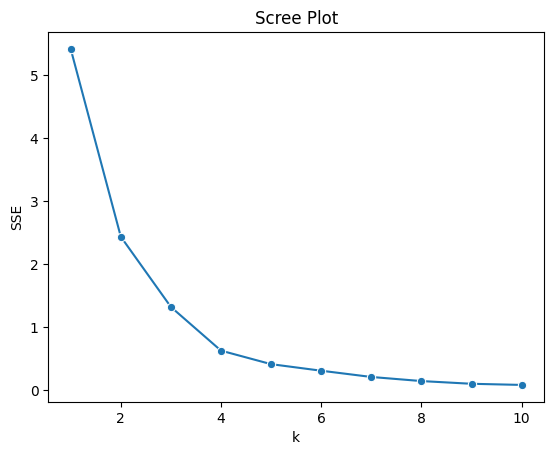

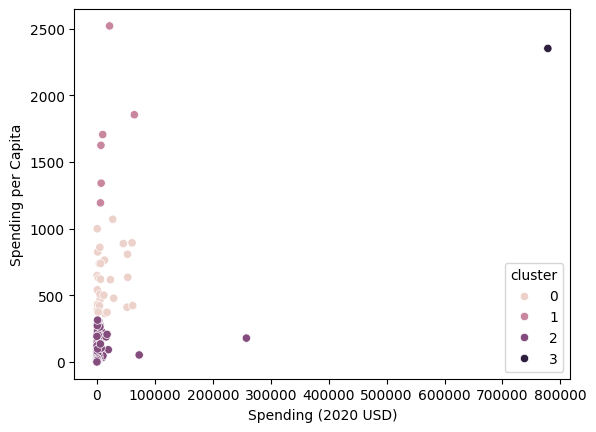

5540    3
Name: cluster, dtype: int32


Spending (2020 USD)                                              \
                      count           mean           std            min   
cluster                                                                   
0                      30.0   17077.591354  20583.053357     405.790494   
1                       6.0   19443.362047  22861.507114    6095.708713   
2                     111.0    4859.185065  25405.739131       8.622460   
3                       1.0  778397.200000           NaN  778397.200000   

                                                                     \
                   25%            50%            75%            max   
cluster                                                               
0          2294.039665    5857.060906   26296.001003   61712.537169   
1          7023.251766    8624.225729   18857.070183   64558.400000   
2           130.010211     382.464677    2297.032353  257973.429834   
3        778397.200000  778397.200000  778397.200000  778397.200000   

        Spending per Capita                                        \
                      count         mean         std          min   
cluster                                                             
0                      30.0   607.478618  206.928757   362.467076   
1                       6.0  1706.721916  466.375705  1193.598730   
2                     111.0    80.061470   83.501824     0.580129   
3                       1.0  2351.631858         NaN  2351.631858   

                                                             
                 25%          50%          75%          max  
cluster                                                      
0         422.208252   579.004604   757.328513  1070.623322  
1        1412.083201  1665.447478  1817.219993  2520.398541  
2          14.880549    47.056944   125.387558   314.201312  
3        2351.631858  2351.631858  2351.631858  2351.631858

In [21]:
#Question 2.2
def scree(X):
    ks = np.arange(1, 11)
    SSE = [KMeans(n_clusters=k, n_init=10, random_state=0).fit(X).inertia_ for k in ks]
    sns.lineplot(x=ks, y=SSE, marker='o').set(title='Scree Plot', xlabel='k', ylabel='SSE')
    plt.show()

cols = ['Spending (2020 USD)', 'Spending per Capita']

X = df[cols]
X = (X - X.min()) / (X.max() - X.min())
scree(X)

df['cluster'] = KMeans(n_clusters=4, n_init=10, random_state=0).fit(X).labels_

sns.scatterplot(data=df, x=cols[0], y=cols[1], hue='cluster')
plt.show()

print(df.loc[df['Country'] == 'United States of America', 'cluster'])
df.groupby('cluster')[cols].describe()

'''
I chose k=4 since the scree plot drops sharply up to k=3-4 and flattens out after that
The united states is in cluster 3. The US spends about 778 billion which is about 30x more than
the next-largest cluster's average. It's such a large outlier that k-means gives it its own cluster.
'''

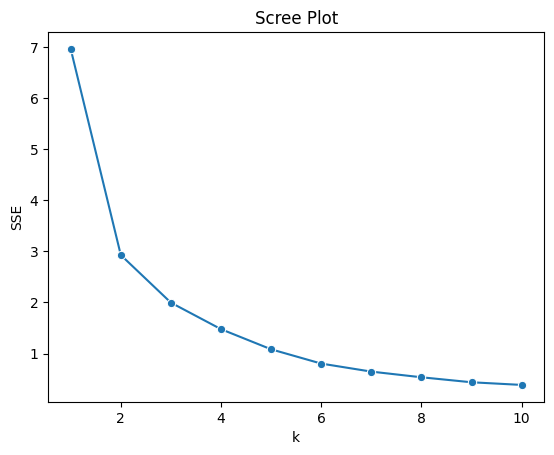

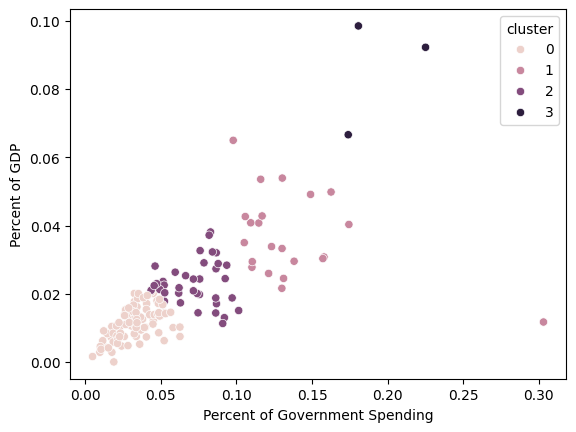

5540    2
Name: cluster, dtype: int32


"\nThe scree plot bends around k = 2–3 and flattens gradually after that, so the elbow is less sharp than in 2.2. \nI used k = 4 for comparison. The clusters are much more balanced (86 / 37 / 22 / 3) and order countries by military “burden”:\n\nLow burden (86): about 3% of government spending and 1% of GDP. Most of Europe, plus China and Australia.\nModerate (37): about 7% of government spending and 2.3% of GDP. The United States is here, along with India, Greece, and Ukraine.\nHigh (22): about 14% and 3.7%. Russia, Israel, Kuwait, Pakistan, Azerbaijan, Armenia, Jordan.\nExtreme (3): Oman, Saudi Arabia, and Algeria, at about 19% of government spending and 8.6% of GDP.\n\nFor comparison, in 2.2 the US was an outlier in its own cluster, but measured relative to its economy it's just a mid-level spender.\nThe clusters now reflect regional security situations (like the middle east, caucasus, russia) as opposed to country size or wealth\n"

In [25]:
#Question 2.3
cols2 = ['Percent of Government Spending', 'Percent of GDP']

X = df[cols2]
X = (X - X.min()) / (X.max() - X.min())
scree(X)

df['cluster'] = KMeans(n_clusters=4, n_init=10, random_state=0).fit(X).labels_

sns.scatterplot(data=df, x=cols2[0], y=cols2[1], hue='cluster')
plt.show()

print(df.loc[df['Country'] == 'United States of America', 'cluster'])
df.groupby('cluster')[cols2].describe()

'''
The scree plot bends around k = 2–3 and flattens gradually after that, so the elbow is less sharp than in 2.2.
I used k = 4 for comparison. The clusters are much more balanced (86 / 37 / 22 / 3) and order countries by military “burden”:

Low burden (86): about 3% of government spending and 1% of GDP. Most of Europe, plus China and Australia.
Moderate (37): about 7% of government spending and 2.3% of GDP. The United States is here, along with India, Greece, and Ukraine.
High (22): about 14% and 3.7%. Russia, Israel, Kuwait, Pakistan, Azerbaijan, Armenia, Jordan.
Extreme (3): Oman, Saudi Arabia, and Algeria, at about 19% of government spending and 8.6% of GDP.

For comparison, in 2.2 the US was an outlier in its own cluster, but measured relative to its economy it's just a mid-level spender.
The clusters now reflect regional security situations (like the middle east, caucasus, russia) as opposed to country size or wealth
'''

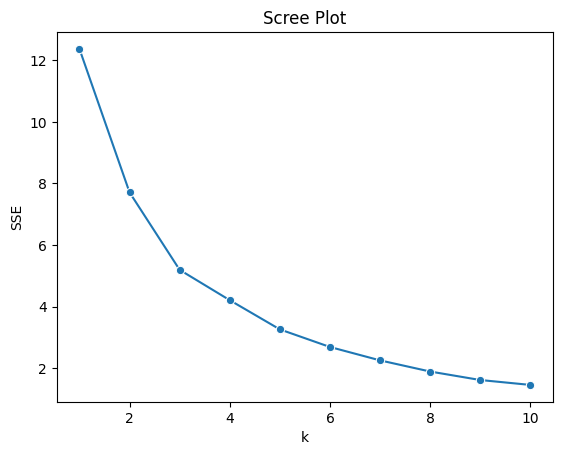

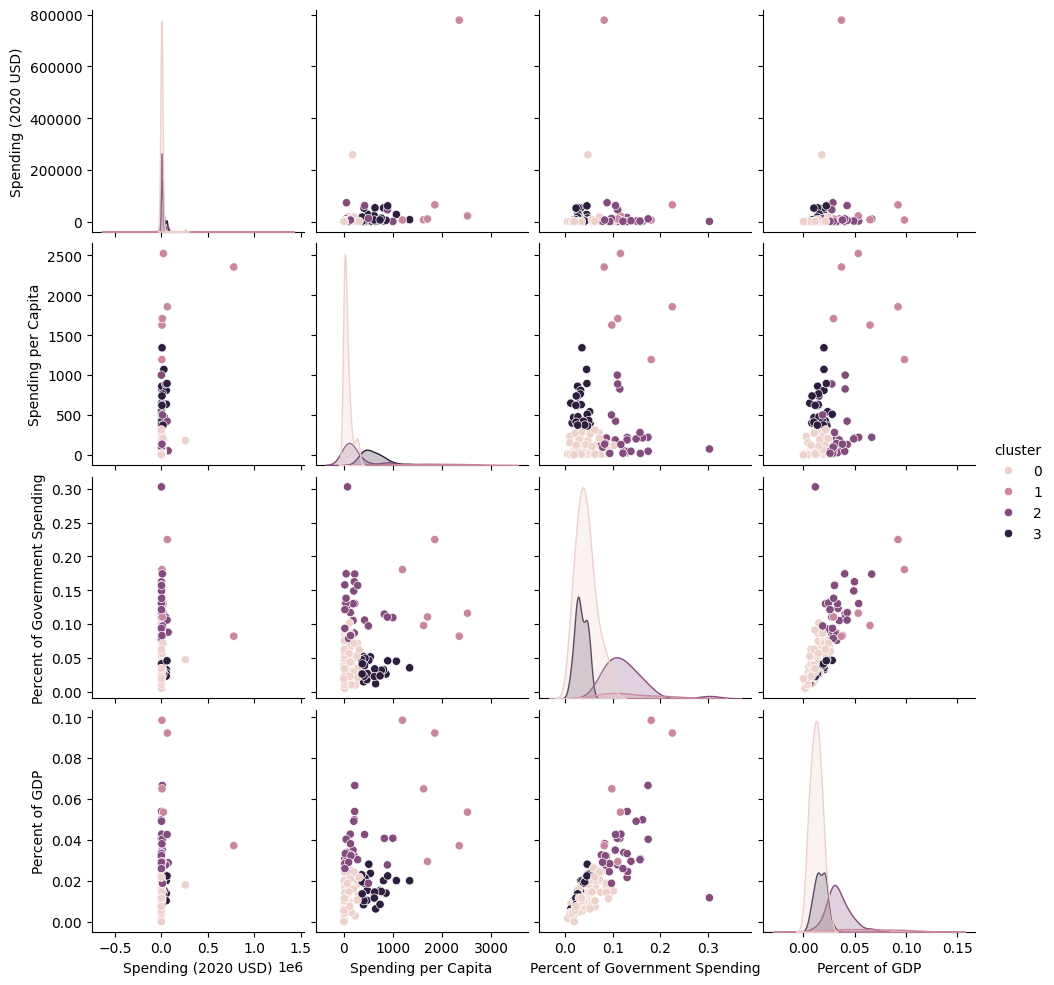

5540    1
Name: cluster, dtype: int32


Spending (2020 USD)                                             \
                      count           mean            std          min   
cluster                                                                  
0                      86.0    4513.543790   27841.230783     8.622460   
1                       6.0  147964.582042  309635.189564  6095.708713   
2                      30.0    9073.543709   18135.032885   163.926877   
3                      26.0   15330.618681   18923.469359   405.790494   

                                                                 \
                 25%           50%           75%            max   
cluster                                                           
0          81.022976    288.061512   1138.618231  257973.429834   
1        7700.424616  15897.570598  53872.942442  778397.200000   
2         522.737081   1663.090134   8646.648849   72937.064048   
3        3176.345598   5857.060906  21818.934764   60675.039625   

        Spending per Capita               ... Percent of Government Spending  \
                      count         mean  ...                            75%   
cluster                                   ...                                  
0                      86.0    70.290644  ...                       0.053006   
1                       6.0  1875.150751  ...                       0.164503   
2                      30.0   215.920971  ...                       0.136403   
3                      26.0   612.677541  ...                       0.044645   

                  Percent of GDP                                          \
              max          count      mean       std       min       25%   
cluster                                                                    
0        0.101501           86.0  0.012481  0.005799  0.000054  0.007811   
1        0.225050            6.0  0.062634  0.028275  0.029429  0.041272   
2        0.303027           30.0  0.034105  0.011116  0.011742  0.027933   
3        0.052209           26.0  0.016585  0.005525  0.006273  0.013689   

                                       
              50%       75%       max  
cluster                                
0        0.012532  0.016783  0.026340  
1        0.059257  0.085398  0.098470  
2        0.032148  0.040637  0.066600  
3        0.015324  0.020431  0.028132  

[4 rows x 32 columns]

In [24]:
# Question 2.4
cols = ['Spending (2020 USD)', 'Spending per Capita',
        'Percent of Government Spending', 'Percent of GDP']
X = df[cols]
X = (X - X.min()) / (X.max() - X.min())

scree(X)

df['cluster'] = KMeans(n_clusters=4, n_init=10, random_state=0).fit(X).labels_

sns.pairplot(df[cols + ['cluster']], hue='cluster')
plt.show()

print(df.loc[df['Country'] == 'United States of America', 'cluster'])
df.groupby('cluster')[cols].describe()

'''
The scree plot has no clear elbow, so k is harder to choose. I kept k=4. The clusters mix both of the views that were discussed earlier
* big, heavy spenders (6) like the us, saudi arabia, israel, kuwait, oman, singapore, are high in both dollars and burden
* high burden, low dollars (30) l;ike russia, algeria, pakistan, ukraine, jordan, azerbaijan
* wealthy, low burden (26): UK, France, poland, greece, australia, norway, are mopderate per capita and low percent of gdp
* low on everything (86)
'''

In [ ]:
#Question 2.5

'''
Partly. k-means separated two different ideas: how much countries spend (dollars and per capita) and how heavily spending weighs on their economies (percentages).
It also showed that the US is an outlier in absolute terms but not relative to its economy.
Combining all four variables gave the most interpretable groups, roughly aligned with wealth and regional security.

The limitations matter, though. The dollar variables are extremely skewed, so in 2.2 a single country used up a whole cluster and 111 countries were lumped together.
The elbows were weak in 2.3 and 2.4, so k = 4 was a judgment call. A log transform of the dollar variables, or a different algorithm
such as the hierarchical clustering in the slides, might give more useful groups.
'''

## *Phase 2: AI-assisted Revision
Keep Phase 1 frozen.

- **Phase 1 commit SHA ID:** [To be provided]
- **AI tool and model used:** [To be provided]

### *Prompts used

1. [Paste prompt]
2. [Paste follow-up prompt]

### *AI-proposed changes


[Paste the AI's concise numbered list verbatim.]

1. ...
2. ...

### *Evaluation of AI suggestions


| Change | Decision | Reason and verification |
|---|---|---|
| 1 | Accept / modify / reject | ... |
| 2 | Accept / modify / reject | ... |

### *AI-assisted solution in full
After the evaluation of AI suggestions, incorporate the accepted revisions into your Phase 1 solution and provide the final Phase 2 solution in full in the following cells.

In [ ]:
# Your Phase 2 solution to the problem goes here.


### *Reflection on AI assistance
In your own words without generative AI.

[In 150–300 words, describe the main improvements, AI mistakes or limitations, how the final solution was verified, and any remaining concerns.]